In [1]:
from langgraph.graph import StateGraph,START,END
from langchain_core.messages import BaseMessage, HumanMessage
from typing import TypedDict , Annotated
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import MemorySaver
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
#add message to retain messages in memory
from langgraph.graph.message import add_messages
class Bot(TypedDict):
    messages : Annotated[list[BaseMessage],add_messages]

In [3]:
import os
llm = ChatGroq(model="openai/gpt-oss-120b",api_key=os.environ.get("GROQ_APIP_KEY"))

def chat(state:Bot):

    messages = state['messages']

    response = llm.invoke(messages)

    return {'messages':[response]}



In [ ]:
checkpointer = MemorySaver()
graph = StateGraph(Bot)

graph.add_node('Chat',chat)

graph.add_edge(START,'Chat')
graph.add_edge('Chat',END)

chatbot = graph.compile(checkpointer=checkpointer)



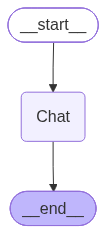

In [5]:
chatbot

In [9]:
## Making continous chats

thread = 1
while True:
    user_message = input("Type Here ...")

    print("Use : ",user_message)

    if user_message.strip().lower() in ['exit','bye','quit']:
        break
    config = {'configurable':{"thread_id" : thread}}

    response = chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)

    print("ChatBot : " , response['messages'][-1].content)


Use :  Hi I am Rushabh
ChatBot :  Hey Rushabh! 👋 Great to meet you. How can I help you today?
Use :  What is my name?
ChatBot :  You told me your name is **Rushabh**. 😊  

Anything specific you’d like to chat about or need help with today, Rushabh?
Use :  What is 100 +124
ChatBot :  100 + 124 = **224**.
Use :  divide it by 24
ChatBot :  \( \displaystyle \frac{224}{24} = \frac{28}{3} = 9\frac{1}{3} \)

In decimal form that’s **9.333…** (repeating).
Use :  round it
ChatBot :  The exact value is 9 ⅓ ≈ 9.333…

- **Rounded to the nearest whole number:** **9**  
- **Rounded to two decimal places:** **9.33**  

Let me know if you need it rounded to a different precision!
Use :  ok bye
ChatBot :  Take care! If you ever need anything else, just drop by. Bye for now!
Use :  bye
